In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os


In [ ]:

folder = "/content/drive/MyDrive/Wafer_Defect_Analysis"
file_path = folder + "/LSWMD.pkl"

if os.path.exists(file_path):
    print("LSWMD.pkl found!")
else:
    raise FileNotFoundError("Check your Google Drive folder and filename.")


LSWMD.pkl found!


In [ ]:

sample_path = folder + "/LSWMD_first10000.pkl"

if os.path.exists(sample_path):
    data = pd.read_pickle(sample_path)
    print("Existing 10,000-row sample loaded.")
else:
    print("Loading original dataset. Please wait...")

    full_data = pd.read_pickle(file_path)
    data = full_data.head(10000).copy()

    data.to_pickle(sample_path)
    del full_data

    print("10,000-row sample created and saved.")

print("Rows:", len(data))
print("Columns:", len(data.columns))
print("Column names:", data.columns.tolist())


Loading original dataset. Please wait...
10,000-row sample created and saved.
Rows: 10000
Columns: 6
Column names: ['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']


In [ ]:

print("Dataset information:")
data.info()

print("\nFirst 5 rows:")
display(data.head())

print("\nMissing values by column:")
print(data.isnull().sum())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   waferMap        10000 non-null  object 
 1   dieSize         10000 non-null  float64
 2   lotName         10000 non-null  object 
 3   waferIndex      10000 non-null  float64
 4   trianTestLabel  10000 non-null  object 
 5   failureType     10000 non-null  object 
dtypes: float64(2), object(4)
memory usage: 468.9+ KB

First 5 rows:


,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],[[none]]



Missing values by column:
waferMap          0
dieSize           0
lotName           0
waferIndex        0
trianTestLabel    0
failureType       0
dtype: int64


In [ ]:

def clean_label(value):
    if value is None:
        return "Unlabelled"

    arr = np.asarray(value, dtype=object).reshape(-1)

    if arr.size == 0:
        return "Unlabelled"

    label = str(arr[0]).strip()

    if label.lower() in ["", "none", "nan"]:
        return "Unlabelled"

    return label

if "failureType" in data.columns:
    data["cleanFailureType"] = data["failureType"].apply(clean_label)

    print("Defect categories:")
    print(data["cleanFailureType"].value_counts())
else:
    print("failureType column not found. Check Step 6.")


Defect categories:
cleanFailureType
Unlabelled    9590
Edge-Loc       151
Loc            115
Edge-Ring       35
Scratch         29
Center          25
Donut           25
Random          22
Near-full        8
Name: count, dtype: int64


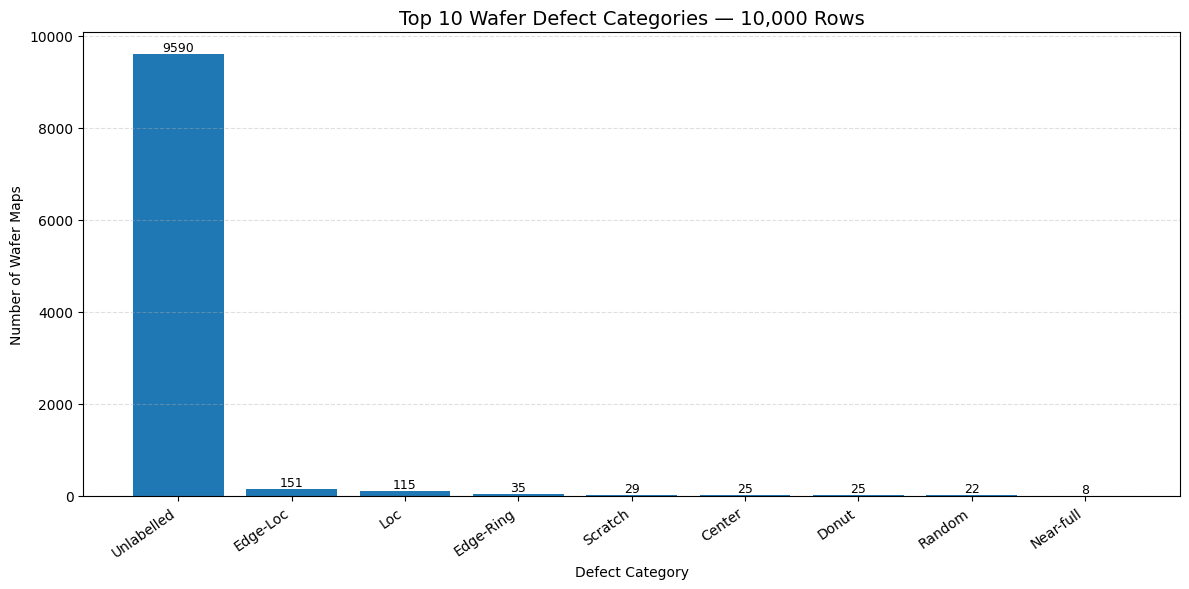

In [ ]:

counts = data["cleanFailureType"].value_counts().head(10)

plt.figure(figsize=(12, 6))
bars = plt.bar(counts.index, counts.values)

plt.title("Top 10 Wafer Defect Categories — 10,000 Rows", fontsize=14)
plt.xlabel("Defect Category")
plt.ylabel("Number of Wafer Maps")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()


Total wafer maps: 10000
Labelled wafer maps: 410
Unlabelled wafer maps: 9590


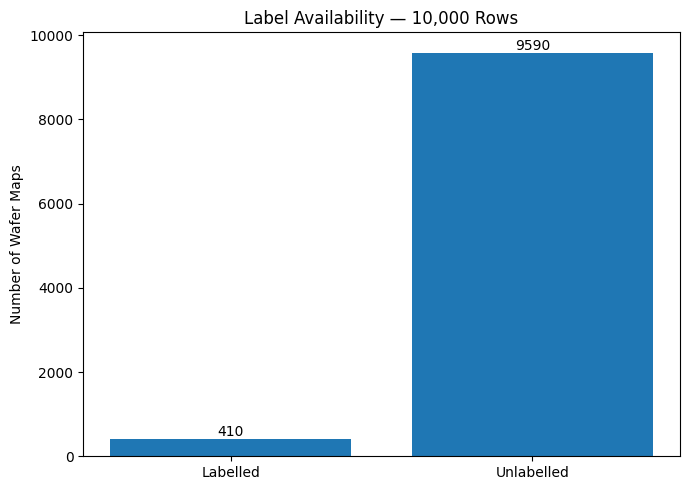

In [ ]:

labelled_count = (data["cleanFailureType"] != "Unlabelled").sum()
unlabelled_count = (data["cleanFailureType"] == "Unlabelled").sum()

print("Total wafer maps:", len(data))
print("Labelled wafer maps:", labelled_count)
print("Unlabelled wafer maps:", unlabelled_count)

plt.figure(figsize=(7, 5))
plt.bar(
    ["Labelled", "Unlabelled"],
    [labelled_count, unlabelled_count]
)

plt.title("Label Availability — 10,000 Rows")
plt.ylabel("Number of Wafer Maps")

for x, value in enumerate([labelled_count, unlabelled_count]):
    plt.text(x, value, str(int(value)), ha="center", va="bottom")

plt.tight_layout()
plt.show()


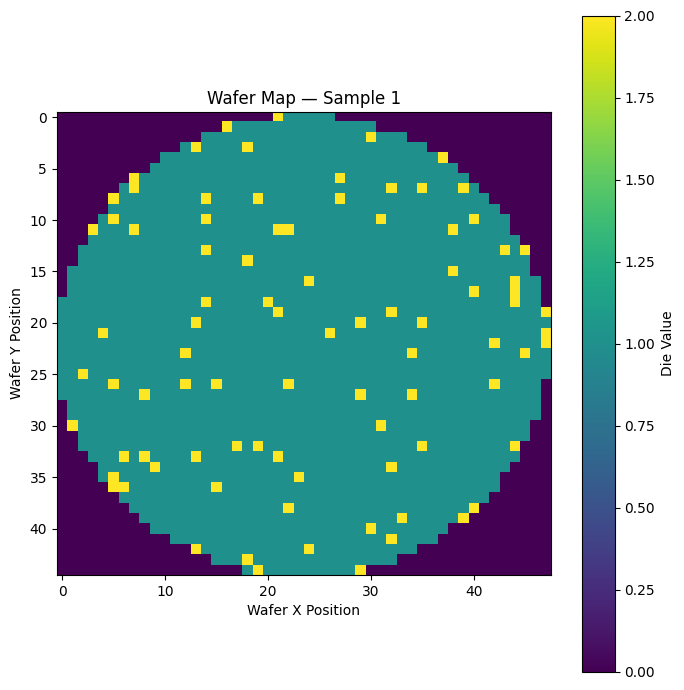

In [ ]:

wafer_map = data.iloc[0]["waferMap"]

plt.figure(figsize=(7, 7))
plt.imshow(
    np.asarray(wafer_map),
    cmap="viridis",
    interpolation="nearest"
)

plt.title("Wafer Map — Sample 1")
plt.xlabel("Wafer X Position")
plt.ylabel("Wafer Y Position")
plt.colorbar(label="Die Value")
plt.tight_layout()
plt.show()


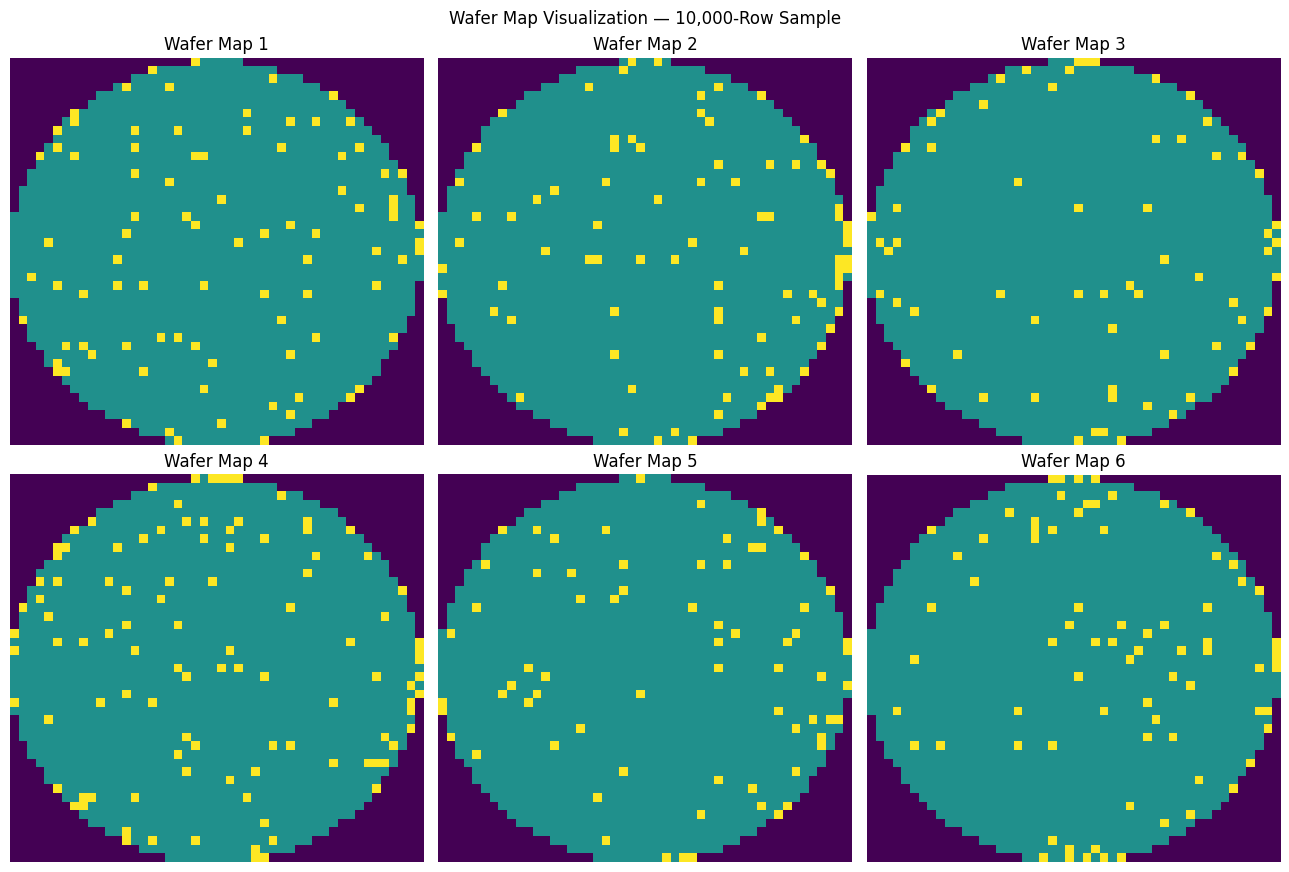

In [ ]:

fig, axes = plt.subplots(2, 3, figsize=(13, 9))

for i, ax in enumerate(axes.flat):
    wafer_map = data.iloc[i]["waferMap"]

    ax.imshow(
        np.asarray(wafer_map),
        cmap="viridis",
        interpolation="nearest"
    )

    ax.set_title(f"Wafer Map {i + 1}")
    ax.axis("off")

plt.suptitle("Wafer Map Visualization — 10,000-Row Sample")
plt.tight_layout()
plt.show()


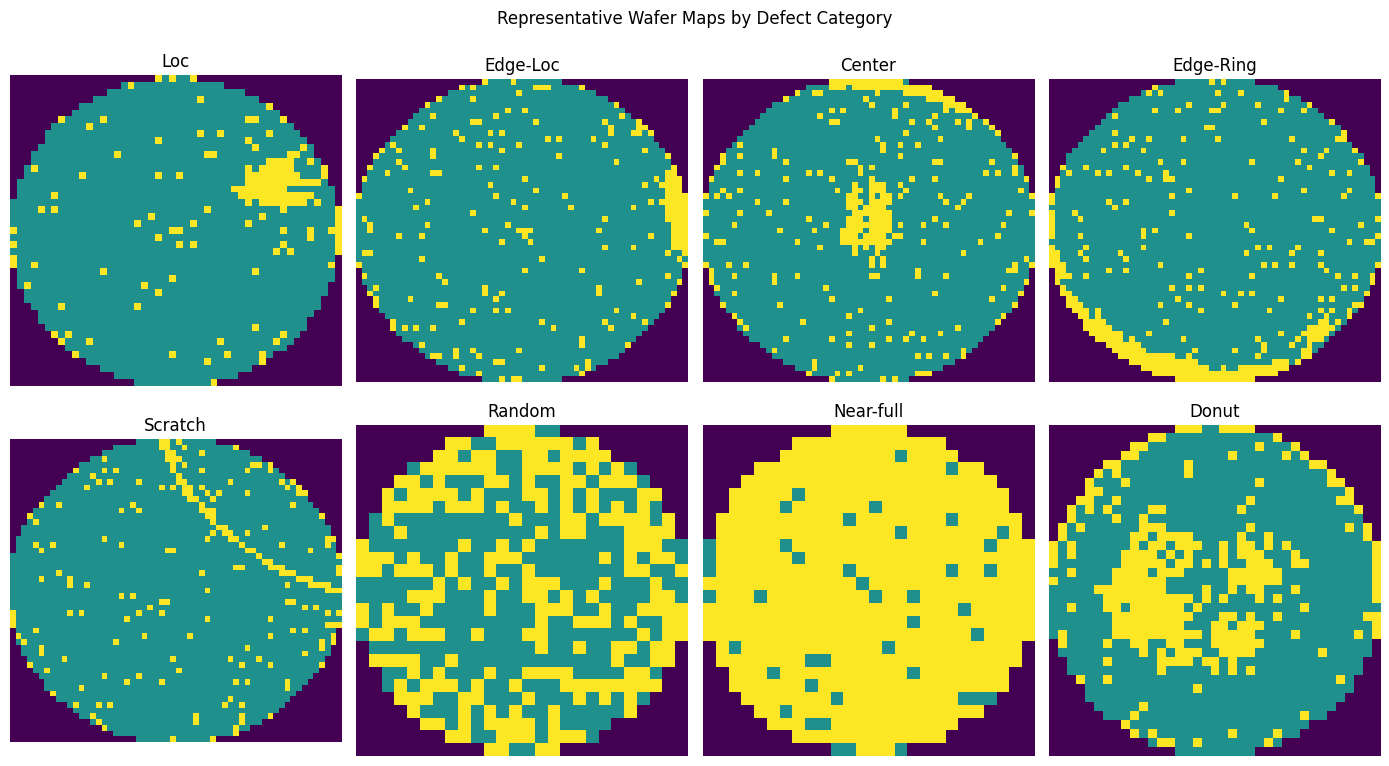

In [ ]:

defect_types = [
    label for label in data["cleanFailureType"].unique()
    if label != "Unlabelled"
]

defect_types = defect_types[:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 8))

for ax, defect in zip(axes.flat, defect_types):
    matching_rows = data[data["cleanFailureType"] == defect]
    wafer_map = matching_rows.iloc[0]["waferMap"]

    ax.imshow(
        np.asarray(wafer_map),
        cmap="viridis",
        interpolation="nearest"
    )

    ax.set_title(str(defect))
    ax.axis("off")

for ax in axes.flat[len(defect_types):]:
    ax.axis("off")

plt.suptitle("Representative Wafer Maps by Defect Category")
plt.tight_layout()
plt.show()


In [ ]:

shapes = data["waferMap"].apply(
    lambda x: str(np.asarray(x).shape) if x is not None else "Missing"
)

print("Wafer-map dimensions across the sample:")
print(shapes.value_counts().head(20))


Wafer-map dimensions across the sample:
waferMap
(26, 26)    7654
(25, 28)     210
(76, 70)     199
(33, 33)     188
(26, 25)     184
(53, 58)     125
(54, 42)     120
(49, 39)     100
(30, 30)      83
(37, 37)      50
(35, 38)      48
(50, 43)      46
(31, 29)      43
(49, 53)      31
(29, 29)      30
(60, 40)      25
(75, 63)      25
(43, 43)      25
(36, 34)      25
(41, 57)      25
Name: count, dtype: int64


In [ ]:

# Save tabular data without the large wafer-map arrays
csv_path = folder + "/LSWMD_first10000.csv"

data.drop(columns=["waferMap"], errors="ignore").to_csv(
    csv_path,
    index=False
)

# Save defect-category counts
data["cleanFailureType"].value_counts().to_csv(
    folder + "/defect_counts_10000.csv",
    header=["Count"]
)

# Save wafer-map dimension counts
shapes.value_counts().to_csv(
    folder + "/wafer_map_dimensions_10000.csv",
    header=["Count"]
)

print("Analysis completed!")
print("Saved files:")
print(sample_path)
print(csv_path)
print(folder + "/defect_counts_10000.csv")
print(folder + "/wafer_map_dimensions_10000.csv")


Analysis completed!
Saved files:
/content/drive/MyDrive/Wafer_Defect_Analysis/LSWMD_first10000.pkl
/content/drive/MyDrive/Wafer_Defect_Analysis/LSWMD_first10000.csv
/content/drive/MyDrive/Wafer_Defect_Analysis/defect_counts_10000.csv
/content/drive/MyDrive/Wafer_Defect_Analysis/wafer_map_dimensions_10000.csv


In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project folder and saved Phase 1 sample
PROJECT_DIR = "/content/drive/MyDrive/Wafer_Defect_Analysis"
SAMPLE_PATH = os.path.join(
    PROJECT_DIR, "LSWMD_first10000.pkl"
)

# Check that Google Drive is mounted
if not os.path.exists(SAMPLE_PATH):
    raise FileNotFoundError(
        f"Sample not found: {SAMPLE_PATH}\n"
        "Check that Google Drive is mounted and the filename is correct."
    )

# Load the existing sample, NOT the original full dataset
df = pd.read_pickle(SAMPLE_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nDefect label counts:")
print(df["cleanFailureType"].value_counts(dropna=False)
      if "cleanFailureType" in df.columns
      else df["failureType"].value_counts(dropna=False))

Dataset shape: (10000, 6)
Columns: ['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']

Defect label counts:
failureType
[[none]]         6383
[[Edge-Loc]]      151
[[Loc]]           115
[[Edge-Ring]]      35
[[Scratch]]        29
                 ... 
[]                  1
[]                  1
[]                  1
[]                  1
[]                  1
Name: count, Length: 3216, dtype: int64


In [ ]:

# Phase 2 — Prepare wafer maps for defect pattern analysis

# Inspect the original failureType values
print("Sample failureType values:")
print(df["failureType"].head(10).tolist())

# Extract a clean label from the original nested label format
def extract_label(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        if len(value) == 0:
            return "Unlabelled"
        value = value[0]

    if value is None:
        return "Unlabelled"

    label = str(value).strip()

    if label.lower() in ["none", "", "nan"]:
        return "Unlabelled"

    return label

df["defect_label"] = df["failureType"].apply(extract_label)

# Keep only wafers with a known defect label
labelled_df = df[df["defect_label"] != "Unlabelled"].copy()

print("\nTotal wafers in sample:", len(df))
print("Wafers with defect labels:", len(labelled_df))
print("Distinct defect categories:",
      labelled_df["defect_label"].nunique())

print("\nLabelled wafer counts:")
print(labelled_df["defect_label"].value_counts())


Sample failureType values:
[array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4'), array([['none']], dtype='<U4')]

Total wafers in sample: 10000
Wafers with defect labels: 6793
Distinct defect categories: 9

Labelled wafer counts:
defect_label
['none']         6383
['Edge-Loc']      151
['Loc']           115
['Edge-Ring']      35
['Scratch']        29
['Center']         25
['Donut']          25
['Random']         22
['Near-full']       8
Name: count, dtype: int64


In [ ]:

# Correctly extract labels from nested NumPy arrays

def extract_label(value):
    while isinstance(value, (list, tuple, np.ndarray)):
        if len(value) == 0:
            return "Unlabelled"
        value = value[0]

    if value is None:
        return "Unlabelled"

    label = str(value).strip()

    if label.lower() in ["none", "", "nan"]:
        return "Unlabelled"

    return label

df["defect_label"] = df["failureType"].apply(extract_label)

# Remove unlabelled wafers
labelled_df = df[df["defect_label"] != "Unlabelled"].copy()

print("Total wafers:", len(df))
print("Unlabelled wafers:",
      (df["defect_label"] == "Unlabelled").sum())
print("Labelled wafers:", len(labelled_df))

print("\nDefect category counts:")
print(labelled_df["defect_label"].value_counts())


Total wafers: 10000
Unlabelled wafers: 9590
Labelled wafers: 410

Defect category counts:
defect_label
Edge-Loc     151
Loc          115
Edge-Ring     35
Scratch       29
Center        25
Donut         25
Random        22
Near-full      8
Name: count, dtype: int64


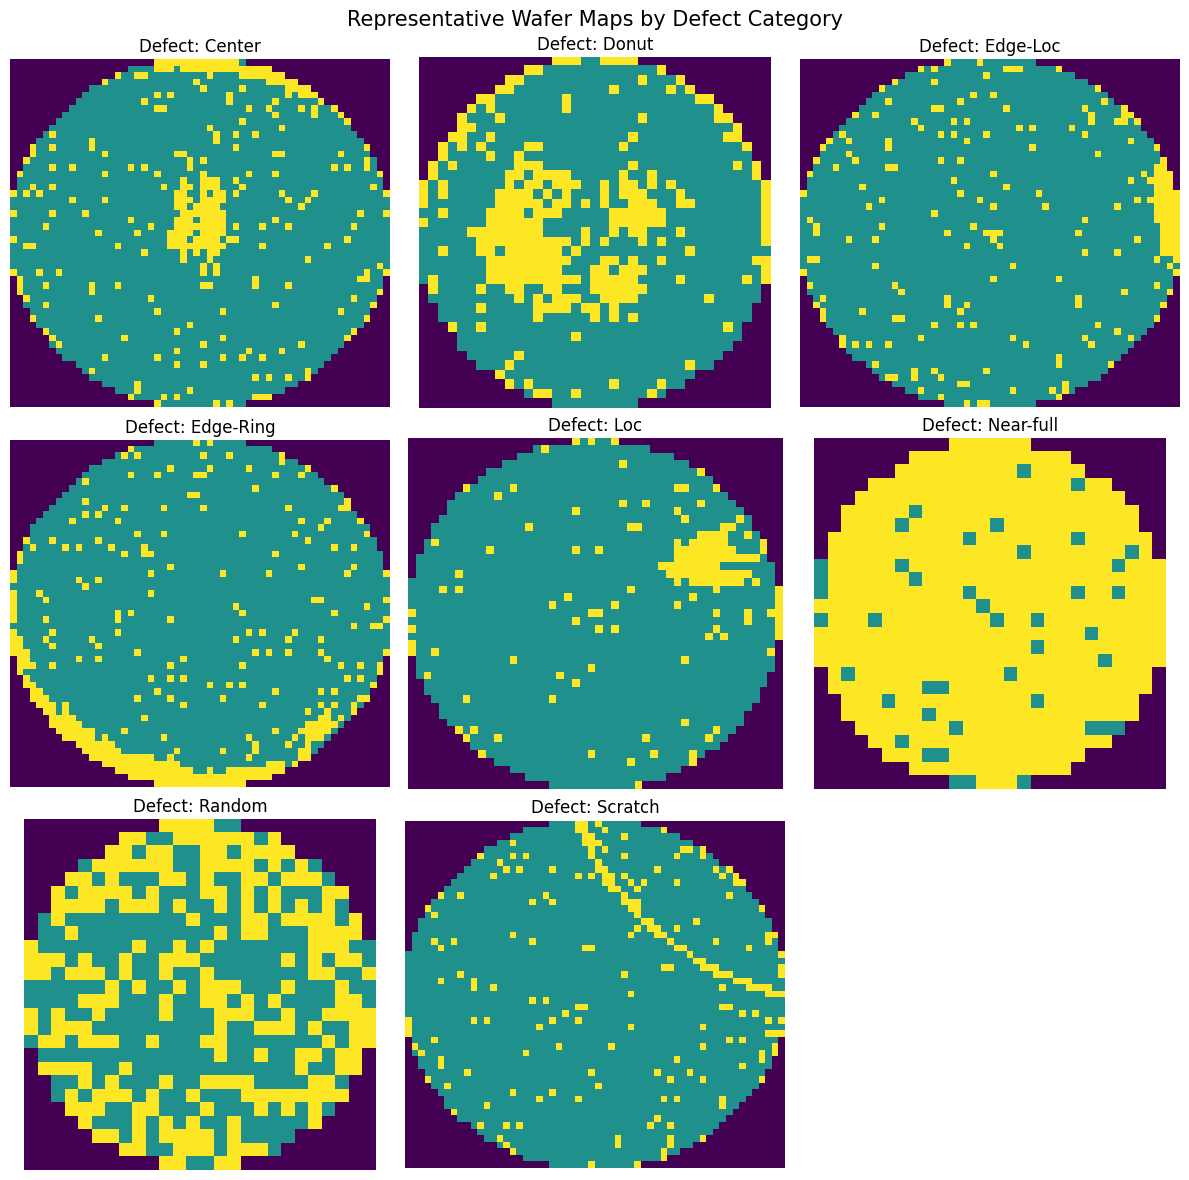

In [ ]:

# Display one representative wafer map per defect category

categories = sorted(labelled_df["defect_label"].unique())

fig, axes = plt.subplots(
    nrows=(len(categories) + 2) // 3,
    ncols=3,
    figsize=(12, 4 * ((len(categories) + 2) // 3))
)

axes = np.array(axes).reshape(-1)

for ax, category in zip(axes, categories):
    row = labelled_df[
        labelled_df["defect_label"] == category
    ].iloc[0]

    wafer_map = np.asarray(row["waferMap"])

    ax.imshow(wafer_map, cmap="viridis", interpolation="nearest")
    ax.set_title(f"Defect: {category}")
    ax.axis("off")

for ax in axes[len(categories):]:
    ax.axis("off")

plt.suptitle("Representative Wafer Maps by Defect Category",
             fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:

# Phase 2 — Quantitative wafer-map pattern analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def analyze_wafer_map(wafer_map):
    wm = np.asarray(wafer_map).squeeze()

    if wm.ndim != 2 or wm.size == 0:
        return None

    # In this dataset, 0 = background, 1 = normal die,
    # and 2 = defective die.
    valid = (wm == 1) | (wm == 2)
    defective = wm == 2

    if valid.sum() == 0:
        return None

    h, w = wm.shape
    yy, xx = np.indices((h, w))
    cy, cx = (h - 1) / 2, (w - 1) / 2

    # Normalize distance from wafer center.
    distance = np.sqrt(
        ((yy - cy) / max(cy, 1)) ** 2 +
        ((xx - cx) / max(cx, 1)) ** 2
    )

    center = distance <= 0.35
    edge = distance >= 0.75

    # Quadrants, using the wafer-map array coordinates.
    top = yy < h / 2
    left = xx < w / 2

    def defect_rate(region):
        mask = valid & region
        return (
            100 * (defective & mask).sum() / mask.sum()
            if mask.sum() else np.nan
        )

    return {
        "map_height": h,
        "map_width": w,
        "valid_die_count": int(valid.sum()),
        "defective_die_count": int((defective & valid).sum()),
        "overall_defect_rate_pct": defect_rate(
            np.ones(wm.shape, dtype=bool)
        ),
        "center_defect_rate_pct": defect_rate(center),
        "edge_defect_rate_pct": defect_rate(edge),
        "top_left_defect_rate_pct": defect_rate(top & left),
        "top_right_defect_rate_pct": defect_rate(top & ~left),
        "bottom_left_defect_rate_pct": defect_rate(~top & left),
        "bottom_right_defect_rate_pct": defect_rate(~top & ~left)
    }

records = []

for idx, row in labelled_df.iterrows():
    metrics = analyze_wafer_map(row["waferMap"])

    if metrics is not None:
        records.append({
            "source_index": idx,
            "defect_label": row["defect_label"],
            **metrics
        })

pattern_df = pd.DataFrame(records)

print("Wafers analyzed:", len(pattern_df))
display(pattern_df.head(10))

print("\nSummary by defect category:")
display(
    pattern_df.groupby("defect_label").agg(
        wafer_count=("source_index", "count"),
        mean_defect_rate_pct=("overall_defect_rate_pct", "mean"),
        mean_center_rate_pct=("center_defect_rate_pct", "mean"),
        mean_edge_rate_pct=("edge_defect_rate_pct", "mean")
    ).round(2)
)


Wafers analyzed: 410


,source_index,defect_label,map_height,map_width,valid_die_count,defective_die_count,overall_defect_rate_pct,center_defect_rate_pct,edge_defect_rate_pct,top_left_defect_rate_pct,top_right_defect_rate_pct,bottom_left_defect_rate_pct,bottom_right_defect_rate_pct
0,19,Loc,45,48,1683,146,8.674985,5.102041,9.677419,4.186047,21.276596,4.306220,4.854369
1,36,Edge-Loc,53,58,2460,219,8.902439,6.071429,13.431542,8.439490,12.361331,7.475083,7.178631
2,37,Edge-Loc,53,58,2460,239,9.715447,7.500000,14.038128,8.280255,15.213946,7.475083,7.679466
3,38,Edge-Loc,53,58,2460,270,10.975610,8.928571,16.551127,8.757962,19.017433,7.308970,8.514190
4,39,Edge-Loc,53,58,2460,274,11.138211,3.571429,18.544194,6.369427,23.454834,6.810631,7.512521
5,40,Loc,53,58,2460,498,20.243902,52.500000,21.143847,20.222930,38.193344,9.136213,12.520868
6,41,Edge-Loc,53,58,2460,332,13.495935,7.142857,23.483536,13.057325,25.990491,8.139535,6.176962
7,42,Edge-Loc,53,58,2460,350,14.227642,14.285714,21.750433,13.853503,25.356577,7.807309,9.348915
8,43,Edge-Loc,53,58,2460,251,10.203252,5.357143,17.071057,10.987261,15.372425,6.478405,7.679466
9,44,Center,53,58,2460,315,12.804878,34.285714,14.038128,13.216561,19.492868,8.471761,9.682805



Summary by defect category:


,wafer_count,mean_defect_rate_pct,mean_center_rate_pct,mean_edge_rate_pct
defect_label,,,,
Center,25,23.50,55.76,18.60
Donut,25,31.69,47.17,12.91
Edge-Loc,151,24.26,18.62,31.70
Edge-Ring,35,26.16,17.44,39.63
Loc,115,16.28,15.35,16.48
Near-full,8,90.06,88.54,90.61
Random,22,49.56,53.44,49.17
Scratch,29,14.91,15.51,17.37


In [ ]:

OUTPUT_DIR = "/content/drive/MyDrive/Wafer_Defect_Analysis/phase2_results"
import os
os.makedirs(OUTPUT_DIR, exist_ok=True)

pattern_df.to_csv(
    os.path.join(OUTPUT_DIR, "wafer_pattern_metrics.csv"),
    index=False
)

print("Saved:", os.path.join(
    OUTPUT_DIR, "wafer_pattern_metrics.csv"
))


Saved: /content/drive/MyDrive/Wafer_Defect_Analysis/phase2_results/wafer_pattern_metrics.csv


In [ ]:

# Verify that Phase 2 results exist and ran successfully

print("Phase 2 metrics available:", "pattern_df" in globals())

if "pattern_df" in globals():
    print("Number of wafers analyzed:", len(pattern_df))
    print("Available columns:")
    print(pattern_df.columns.tolist())
    display(pattern_df.head())
else:
    print("Run the Phase 2 quantitative analysis cell first.")


Phase 2 metrics available: True
Number of wafers analyzed: 410
Available columns:
['source_index', 'defect_label', 'map_height', 'map_width', 'valid_die_count', 'defective_die_count', 'overall_defect_rate_pct', 'center_defect_rate_pct', 'edge_defect_rate_pct', 'top_left_defect_rate_pct', 'top_right_defect_rate_pct', 'bottom_left_defect_rate_pct', 'bottom_right_defect_rate_pct']


,source_index,defect_label,map_height,map_width,valid_die_count,defective_die_count,overall_defect_rate_pct,center_defect_rate_pct,edge_defect_rate_pct,top_left_defect_rate_pct,top_right_defect_rate_pct,bottom_left_defect_rate_pct,bottom_right_defect_rate_pct
0,19,Loc,45,48,1683,146,8.674985,5.102041,9.677419,4.186047,21.276596,4.306220,4.854369
1,36,Edge-Loc,53,58,2460,219,8.902439,6.071429,13.431542,8.439490,12.361331,7.475083,7.178631
2,37,Edge-Loc,53,58,2460,239,9.715447,7.500000,14.038128,8.280255,15.213946,7.475083,7.679466
3,38,Edge-Loc,53,58,2460,270,10.975610,8.928571,16.551127,8.757962,19.017433,7.308970,8.514190
4,39,Edge-Loc,53,58,2460,274,11.138211,3.571429,18.544194,6.369427,23.454834,6.810631,7.512521


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Check the wafer-map encoding before interpreting metrics
sample_encodings = set()

for wm in labelled_df["waferMap"].head(100):
    arr = np.asarray(wm).squeeze()
    if arr.ndim == 2:
        sample_encodings.update(np.unique(arr).tolist())

print("Observed wafer-map values in first 100 labelled maps:",
      sorted(sample_encodings))

# Continue only if the expected encoding is present
if not sample_encodings.issubset({0, 1, 2}):
    raise ValueError(
        "Unexpected wafer-map encoding. Inspect the values before proceeding."
    )

def calculate_metrics(wm):
    arr = np.asarray(wm).squeeze()

    if arr.ndim != 2:
        return None

    valid = (arr == 1) | (arr == 2)
    defective = arr == 2

    valid_count = int(valid.sum())
    defect_count = int((defective & valid).sum())

    if valid_count == 0:
        return None

    h, w = arr.shape
    yy, xx = np.indices(arr.shape)
    cy, cx = (h - 1) / 2, (w - 1) / 2

    distance = np.sqrt(
        ((yy - cy) / max(cy, 1)) ** 2 +
        ((xx - cx) / max(cx, 1)) ** 2
    )

    center_mask = valid & (distance <= 0.35)
    edge_mask = valid & (distance >= 0.75)

    center_defects = int((defective & center_mask).sum())
    edge_defects = int((defective & edge_mask).sum())

    return {
        "valid_die_count": valid_count,
        "defective_die_count": defect_count,
        "defect_rate_pct": 100 * defect_count / valid_count,
        "center_defect_rate_pct": (
            100 * center_defects / center_mask.sum()
            if center_mask.sum() else np.nan
        ),
        "edge_defect_rate_pct": (
            100 * edge_defects / edge_mask.sum()
            if edge_mask.sum() else np.nan
        ),
        "center_defect_share_pct": (
            100 * center_defects / defect_count
            if defect_count else 0
        ),
        "edge_defect_share_pct": (
            100 * edge_defects / defect_count
            if defect_count else 0
        )
    }

metric_records = []

for idx, row in labelled_df.iterrows():
    result = calculate_metrics(row["waferMap"])

    if result is not None:
        metric_records.append({
            "source_index": idx,
            "defect_label": row["defect_label"],
            **result
        })

phase3_df = pd.DataFrame(metric_records)

print("Wafers with valid metrics:", len(phase3_df))
display(phase3_df.head(10))


Observed wafer-map values in first 100 labelled maps: [0, 1, 2]
Wafers with valid metrics: 410


,source_index,defect_label,valid_die_count,defective_die_count,defect_rate_pct,center_defect_rate_pct,edge_defect_rate_pct,center_defect_share_pct,edge_defect_share_pct
0,19,Loc,1683,146,8.674985,5.102041,9.677419,6.849315,51.369863
1,36,Edge-Loc,2460,219,8.902439,6.071429,13.431542,7.762557,70.776256
2,37,Edge-Loc,2460,239,9.715447,7.500000,14.038128,8.786611,67.782427
3,38,Edge-Loc,2460,270,10.975610,8.928571,16.551127,9.259259,70.740741
4,39,Edge-Loc,2460,274,11.138211,3.571429,18.544194,3.649635,78.102190
5,40,Loc,2460,498,20.243902,52.500000,21.143847,29.518072,48.995984
6,41,Edge-Loc,2460,332,13.495935,7.142857,23.483536,6.024096,81.626506
7,42,Edge-Loc,2460,350,14.227642,14.285714,21.750433,11.428571,71.714286
8,43,Edge-Loc,2460,251,10.203252,5.357143,17.071057,5.976096,78.486056
9,44,Center,2460,315,12.804878,34.285714,14.038128,30.476190,51.428571


In [ ]:

category_summary = phase3_df.groupby("defect_label").agg(
    wafer_count=("source_index", "count"),
    mean_defect_rate_pct=("defect_rate_pct", "mean"),
    median_defect_rate_pct=("defect_rate_pct", "median"),
    mean_center_rate_pct=("center_defect_rate_pct", "mean"),
    mean_edge_rate_pct=("edge_defect_rate_pct", "mean"),
    mean_center_share_pct=("center_defect_share_pct", "mean"),
    mean_edge_share_pct=("edge_defect_share_pct", "mean")
).round(2)

display(category_summary)


,wafer_count,mean_defect_rate_pct,median_defect_rate_pct,mean_center_rate_pct,mean_edge_rate_pct,mean_center_share_pct,mean_edge_share_pct
defect_label,,,,,,,
Center,25,23.50,22.70,55.76,18.60,26.25,41.87
Donut,25,31.69,31.57,47.17,12.91,17.72,18.96
Edge-Loc,151,24.26,22.89,18.62,31.70,8.42,63.79
Edge-Ring,35,26.16,26.73,17.44,39.63,7.53,71.81
Loc,115,16.28,16.70,15.35,16.48,8.68,43.82
Near-full,8,90.06,91.46,88.54,90.61,11.08,48.51
Random,22,49.56,50.38,53.44,49.17,12.41,47.54
Scratch,29,14.91,15.57,15.51,17.37,12.05,56.78


<Figure size 1200x600 with 0 Axes>

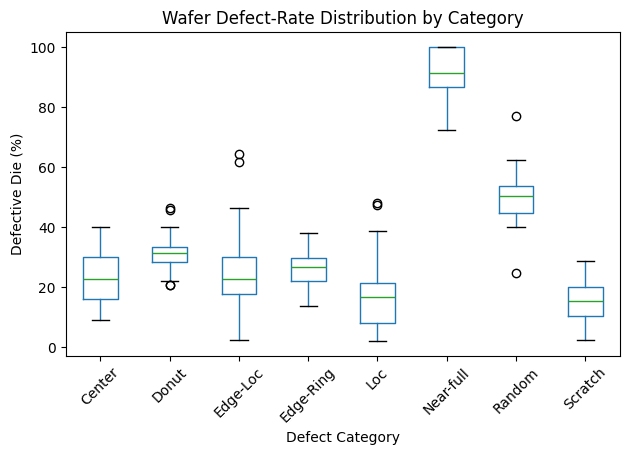

In [ ]:

plt.figure(figsize=(12, 6))

phase3_df.boxplot(
    column="defect_rate_pct",
    by="defect_label",
    rot=45,
    grid=False
)

plt.title("Wafer Defect-Rate Distribution by Category")
plt.suptitle("")
plt.xlabel("Defect Category")
plt.ylabel("Defective Die (%)")
plt.tight_layout()
plt.show()


In [ ]:

OUTPUT_DIR = (
    "/content/drive/MyDrive/"
    "Wafer_Defect_Analysis/phase3_results"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

phase3_df.to_csv(
    os.path.join(OUTPUT_DIR, "wafer_defect_metrics.csv"),
    index=False
)

category_summary.to_csv(
    os.path.join(OUTPUT_DIR, "defect_category_summary.csv")
)

print("Phase 3 results saved to:", OUTPUT_DIR)


Phase 3 results saved to: /content/drive/MyDrive/Wafer_Defect_Analysis/phase3_results


In [ ]:

# Phase 4 — Dataset suitability check

print("Labelled wafers:", len(labelled_df))
print("\nClass counts:")
print(labelled_df["defect_label"].value_counts())

print("\nWafer-map shape distribution:")
shape_counts = labelled_df["waferMap"].apply(
    lambda wm: np.asarray(wm).squeeze().shape
).value_counts()

print(shape_counts.head(15))

print("\nTotal distinct map shapes:", len(shape_counts))


Labelled wafers: 410

Class counts:
defect_label
Edge-Loc     151
Loc          115
Edge-Ring     35
Scratch       29
Center        25
Donut         25
Random        22
Near-full      8
Name: count, dtype: int64

Wafer-map shape distribution:
waferMap
(26, 26)    210
(60, 40)     25
(37, 37)     19
(39, 39)     16
(43, 43)     15
(53, 58)     15
(54, 71)     13
(29, 29)     12
(37, 55)     11
(36, 34)     10
(42, 43)      9
(62, 75)      9
(54, 42)      7
(50, 43)      6
(35, 38)      4
Name: count, dtype: int64

Total distinct map shapes: 32


In [ ]:

# PHASE 4 — STEP 1: Prepare data for classification

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Use the quantitative metrics created in Phase 3
ml_df = phase3_df.copy()

# Remove rows without a known defect category
ml_df = ml_df[
    ml_df["defect_label"].notna()
    & (ml_df["defect_label"] != "none")
].copy()

# Select numerical features already calculated in Phase 3
feature_cols = [
    "valid_die_count",
    "defective_die_count",
    "defect_rate_pct",
    "center_defect_rate_pct",
    "edge_defect_rate_pct",
    "center_defect_share_pct",
    "edge_defect_share_pct"
]

# Keep only columns that exist in your DataFrame
feature_cols = [c for c in feature_cols if c in ml_df.columns]

X = ml_df[feature_cols].replace([np.inf, -np.inf], np.nan)
y = ml_df["defect_label"].astype(str)

print("Dataset shape:", ml_df.shape)
print("Features used:", feature_cols)
print("\nClass counts:")
print(y.value_counts())
print("\nMissing feature values:", int(X.isna().sum().sum()))


Dataset shape: (410, 9)
Features used: ['valid_die_count', 'defective_die_count', 'defect_rate_pct', 'center_defect_rate_pct', 'edge_defect_rate_pct', 'center_defect_share_pct', 'edge_defect_share_pct']

Class counts:
defect_label
Edge-Loc     151
Loc          115
Edge-Ring     35
Scratch       29
Center        25
Donut         25
Random        22
Near-full      8
Name: count, dtype: int64

Missing feature values: 0


In [ ]:

# PHASE 4 — STEP 2: Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())


Training samples: 328
Testing samples: 82

Training class counts:
defect_label
Edge-Loc     121
Loc           92
Edge-Ring     28
Scratch       23
Center        20
Donut         20
Random        18
Near-full      6
Name: count, dtype: int64

Testing class counts:
defect_label
Edge-Loc     30
Loc          23
Edge-Ring     7
Scratch       6
Donut         5
Center        5
Random        4
Near-full     2
Name: count, dtype: int64


In [ ]:

# PHASE 4 — STEP 3: Train Random Forest classifier

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Predict defect categories for unseen test samples
y_pred = rf_model.predict(X_test)

print("Random Forest training completed successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X_train.shape[1])
print("Number of trees:", 200)


Random Forest training completed successfully!
Training samples: 328
Testing samples: 82
Number of features: 7
Number of trees: 200


MODEL EVALUATION RESULTS
----------------------------------------
Accuracy:          0.6829 (68.29%)
Balanced accuracy: 0.6105 (61.05%)
Macro F1-score:    0.5887

Classification Report:
              precision    recall  f1-score   support

      Center       0.83      1.00      0.91         5
       Donut       1.00      0.80      0.89         5
    Edge-Loc       0.71      0.73      0.72        30
   Edge-Ring       0.67      0.57      0.62         7
         Loc       0.73      0.70      0.71        23
   Near-full       0.00      0.00      0.00         2
      Random       0.38      0.75      0.50         4
     Scratch       0.40      0.33      0.36         6

    accuracy                           0.68        82
   macro avg       0.59      0.61      0.59        82
weighted avg       0.68      0.68      0.68        82



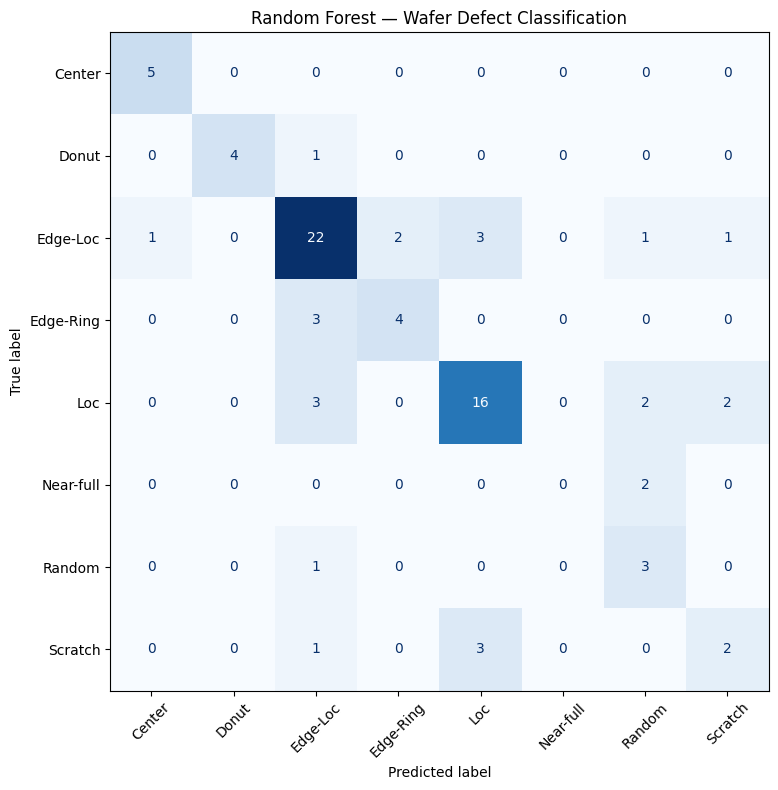

In [ ]:

# PHASE 4 — STEP 4: Evaluate the classifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print("MODEL EVALUATION RESULTS")
print("-" * 40)
print(f"Accuracy:          {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Balanced accuracy: {balanced_acc:.4f} ({balanced_acc * 100:.2f}%)")
print(f"Macro F1-score:    {macro_f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Plot confusion matrix
class_names = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=class_names)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Random Forest — Wafer Defect Classification")
plt.tight_layout()
plt.show()


In [ ]:

# PHASE 4 — STEP 6: Save model evaluation results

import os
import pandas as pd
from sklearn.metrics import classification_report

output_dir = (
    "/content/drive/MyDrive/Wafer_Defect_Analysis/"
    "phase4_results"
)
os.makedirs(output_dir, exist_ok=True)

# Save overall metrics
metrics_df = pd.DataFrame([{
    "model": "Random Forest",
    "training_samples": len(X_train),
    "testing_samples": len(X_test),
    "features": X_train.shape[1],
    "accuracy": accuracy,
    "balanced_accuracy": balanced_acc,
    "macro_f1": macro_f1
}])

metrics_df.to_csv(
    os.path.join(output_dir, "model_metrics.csv"),
    index=False
)

# Save detailed per-class report
report_dict = classification_report(
    y_test, y_pred, output_dict=True, zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv(
    os.path.join(output_dir, "classification_report.csv")
)

# Save actual and predicted labels for the test set
predictions_df = pd.DataFrame({
    "actual_label": y_test.to_numpy(),
    "predicted_label": y_pred
})

predictions_df.to_csv(
    os.path.join(output_dir, "test_predictions.csv"),
    index=False
)

print("Evaluation results saved successfully.")
print("Output folder:", output_dir)
print("\nFiles saved:")
print("- model_metrics.csv")
print("- classification_report.csv")
print("- test_predictions.csv")


Evaluation results saved successfully.
Output folder: /content/drive/MyDrive/Wafer_Defect_Analysis/phase4_results

Files saved:
- model_metrics.csv
- classification_report.csv
- test_predictions.csv



Dataset index: 19
Defect label: Loc
Map shape: (45, 48)
Unique values and counts: {np.uint8(0): np.int64(477), np.uint8(1): np.int64(1537), np.uint8(2): np.int64(146)}

Dataset index: 36
Defect label: Edge-Loc
Map shape: (53, 58)
Unique values and counts: {np.uint8(0): np.int64(614), np.uint8(1): np.int64(2241), np.uint8(2): np.int64(219)}

Dataset index: 37
Defect label: Edge-Loc
Map shape: (53, 58)
Unique values and counts: {np.uint8(0): np.int64(614), np.uint8(1): np.int64(2221), np.uint8(2): np.int64(239)}

Dataset index: 38
Defect label: Edge-Loc
Map shape: (53, 58)
Unique values and counts: {np.uint8(0): np.int64(614), np.uint8(1): np.int64(2190), np.uint8(2): np.int64(270)}

Dataset index: 39
Defect label: Edge-Loc
Map shape: (53, 58)
Unique values and counts: {np.uint8(0): np.int64(614), np.uint8(1): np.int64(2186), np.uint8(2): np.int64(274)}


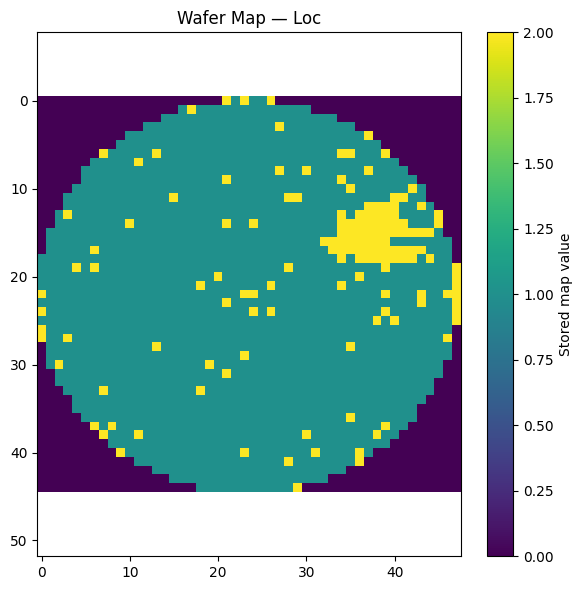

In [ ]:

# PHASE 5 — STEP 1: Inspect wafer-map values

import numpy as np
import matplotlib.pyplot as plt

# Inspect several labelled wafer maps
sample_indices = labelled_df.index[:5]

for idx in sample_indices:
    wafer_map = np.asarray(
        labelled_df.loc[idx, "waferMap"]
    ).squeeze()

    print(f"\nDataset index: {idx}")
    print("Defect label:", labelled_df.loc[idx, "defect_label"])
    print("Map shape:", wafer_map.shape)
    print("Unique values and counts:",
          dict(zip(*np.unique(wafer_map, return_counts=True))))

# Display one labelled wafer map
idx = sample_indices[0]
wafer_map = np.asarray(
    labelled_df.loc[idx, "waferMap"]
).squeeze()

plt.figure(figsize=(6, 6))
plt.imshow(wafer_map, interpolation="nearest")
plt.title(
    f"Wafer Map — {labelled_df.loc[idx, 'defect_label']}"
)
plt.colorbar(label="Stored map value")
plt.axis("equal")
plt.tight_layout()
plt.show()


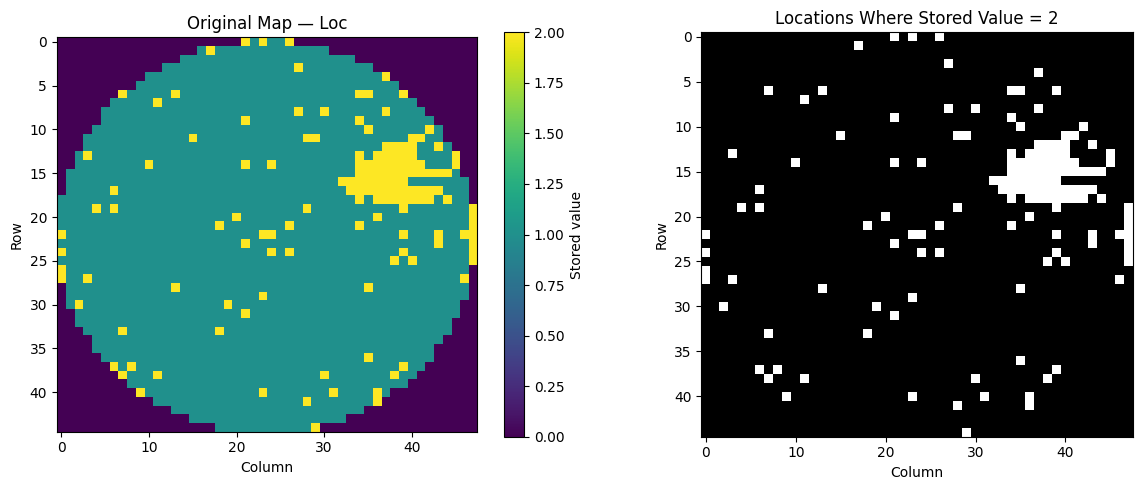

Stored value counts:
Value 0: 477 cells
Value 1: 1537 cells
Value 2: 146 cells


In [ ]:

# PHASE 5 — STEP 2: Visualize stored wafer-map values

import numpy as np
import matplotlib.pyplot as plt

# Use the first wafer from your previous inspection
idx = sample_indices[0]
wm = np.asarray(labelled_df.loc[idx, "waferMap"]).squeeze()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original stored values
im = axes[0].imshow(wm, interpolation="nearest")
axes[0].set_title(
    f"Original Map — {labelled_df.loc[idx, 'defect_label']}"
)
axes[0].set_xlabel("Column")
axes[0].set_ylabel("Row")
fig.colorbar(im, ax=axes[0], label="Stored value")

# Binary view of value 2
axes[1].imshow(wm == 2, cmap="gray", interpolation="nearest")
axes[1].set_title("Locations Where Stored Value = 2")
axes[1].set_xlabel("Column")
axes[1].set_ylabel("Row")

plt.tight_layout()
plt.show()

print("Stored value counts:")
values, counts = np.unique(wm, return_counts=True)
for value, count in zip(values, counts):
    print(f"Value {value}: {count} cells")


Dataset index: 19
Failure label: Loc
Wafer-map shape: (45, 48)
Unique values: [0 1 2]
Value 0: 477 cells (22.08%)
Value 1: 1537 cells (71.16%)
Value 2: 146 cells (6.76%)


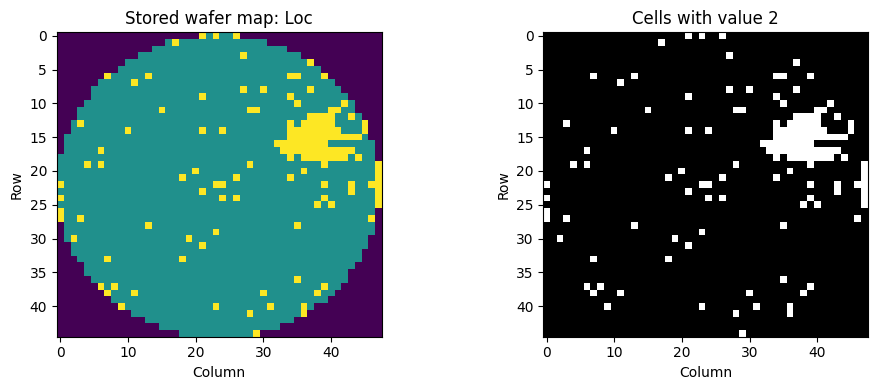

In [ ]:

# PHASE 5 — STEP 3: Check wafer-map values and label

idx = sample_indices[0]

row = labelled_df.loc[idx]
wm = np.asarray(row["waferMap"]).squeeze()

print("Dataset index:", idx)
print("Failure label:", row["defect_label"])
print("Wafer-map shape:", wm.shape)
print("Unique values:", np.unique(wm))

# Show the proportion of each stored value
values, counts = np.unique(wm, return_counts=True)
total = counts.sum()

for value, count in zip(values, counts):
    print(
        f"Value {value}: {count} cells "
        f"({count / total * 100:.2f}%)"
    )

# Compare the map with a view of value 2
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(wm, interpolation="nearest")
axes[0].set_title(f"Stored wafer map: {row['defect_label']}")

axes[1].imshow(wm == 2, cmap="gray", interpolation="nearest")
axes[1].set_title("Cells with value 2")

for ax in axes:
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")

plt.tight_layout()
plt.show()


In [ ]:

# PHASE 5 — STEP 4: Validate defect metrics

idx = sample_indices[0]
wm = np.asarray(labelled_df.loc[idx, "waferMap"]).squeeze()

# Documented WM-811K encoding
valid_die_count = int(np.count_nonzero(wm != 0))
defective_die_count = int(np.count_nonzero(wm == 2))

calculated_defect_rate = (
    defective_die_count / valid_die_count * 100
    if valid_die_count else 0
)

print("Dataset index:", idx)
print("Defect label:", labelled_df.loc[idx, "defect_label"])
print("Valid die count:", valid_die_count)
print("Defective die count:", defective_die_count)
print(f"Recalculated defect rate: {calculated_defect_rate:.2f}%")

# Compare with your Phase 3 metrics, if available
if "phase3_df" in globals() and idx in phase3_df.index:
    print("\nPreviously saved Phase 3 values:")
    print(phase3_df.loc[idx])


Dataset index: 19
Defect label: Loc
Valid die count: 1683
Defective die count: 146
Recalculated defect rate: 8.67%

Previously saved Phase 3 values:
source_index                     381
defect_label                Edge-Loc
valid_die_count                  533
defective_die_count              161
defect_rate_pct            30.206379
center_defect_rate_pct          25.0
edge_defect_rate_pct       34.241245
center_defect_share_pct      9.31677
edge_defect_share_pct      54.658385
Name: 19, dtype: object


In [ ]:

# FIX: Recalculate metrics with labels and wafer maps aligned

import numpy as np
import pandas as pd

corrected_rows = []

for idx, row in labelled_df.iterrows():
    wm = np.asarray(row["waferMap"]).squeeze()

    # WM-811K encoding: 0 = no die, 1 = normal, 2 = defective
    valid_mask = wm != 0
    defect_mask = wm == 2

    valid_count = int(valid_mask.sum())
    defect_count = int(defect_mask.sum())

    if valid_count == 0:
        continue

    rows, cols = wm.shape
    rr, cc = np.indices(wm.shape)

    # Normalize coordinates around the wafer-map centre
    center_mask = (
        ((rr - (rows - 1) / 2) / max(rows / 2, 1)) ** 2
        + ((cc - (cols - 1) / 2) / max(cols / 2, 1)) ** 2
    ) <= 0.5 ** 2

    edge_mask = valid_mask & ~center_mask
    center_valid = valid_mask & center_mask

    center_defects = int((defect_mask & center_mask).sum())
    edge_defects = int((defect_mask & edge_mask).sum())

    corrected_rows.append({
        "source_index": idx,
        "defect_label": str(row["defect_label"]),
        "valid_die_count": valid_count,
        "defective_die_count": defect_count,
        "defect_rate_pct": 100 * defect_count / valid_count,
        "center_defect_rate_pct": (
            100 * center_defects / center_valid.sum()
            if center_valid.sum() else 0
        ),
        "edge_defect_rate_pct": (
            100 * edge_defects / edge_mask.sum()
            if edge_mask.sum() else 0
        ),
        "center_defect_share_pct": (
            100 * center_defects / defect_count
            if defect_count else 0
        ),
        "edge_defect_share_pct": (
            100 * edge_defects / defect_count
            if defect_count else 0
        )
    })

corrected_df = pd.DataFrame(corrected_rows).reset_index(drop=True)

print("Corrected dataset shape:", corrected_df.shape)
print("\nDefect category counts:")
print(corrected_df["defect_label"].value_counts())
print("\nFirst five corrected records:")
print(corrected_df.head())


Corrected dataset shape: (410, 9)

Defect category counts:
defect_label
Edge-Loc     151
Loc          115
Edge-Ring     35
Scratch       29
Center        25
Donut         25
Random        22
Near-full      8
Name: count, dtype: int64

First five corrected records:
   source_index defect_label  valid_die_count  defective_die_count  \
0            19          Loc             1683                  146   
1            36     Edge-Loc             2460                  219   
2            37     Edge-Loc             2460                  239   
3            38     Edge-Loc             2460                  270   
4            39     Edge-Loc             2460                  274   

   defect_rate_pct  center_defect_rate_pct  edge_defect_rate_pct  \
0         8.674985                4.716981             10.007943   
1         8.902439                4.455446             10.355987   
2         9.715447                6.270627             10.841424   
3        10.975610                6.270627

In [ ]:

# PHASE 5 — STEP 2: Train and evaluate using corrected metrics

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

feature_cols = [
    "valid_die_count",
    "defective_die_count",
    "defect_rate_pct",
    "center_defect_rate_pct",
    "edge_defect_rate_pct",
    "center_defect_share_pct",
    "edge_defect_share_pct"
]

X_corrected = corrected_df[feature_cols]
y_corrected = corrected_df["defect_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X_corrected,
    y_corrected,
    test_size=0.20,
    random_state=42,
    stratify=y_corrected
)

corrected_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

corrected_model.fit(X_train, y_train)
y_pred = corrected_model.predict(X_test)

print("Corrected model evaluation")
print("-" * 35)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1-score: {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))


Corrected model evaluation
-----------------------------------
Accuracy: 0.5732
Balanced accuracy: 0.5043
Macro F1-score: 0.4664

Classification report:
              precision    recall  f1-score   support

      Center       0.67      0.80      0.73         5
       Donut       0.80      0.80      0.80         5
    Edge-Loc       0.65      0.67      0.66        30
   Edge-Ring       0.40      0.29      0.33         7
         Loc       0.65      0.57      0.60        23
   Near-full       0.00      0.00      0.00         2
      Random       0.30      0.75      0.43         4
     Scratch       0.20      0.17      0.18         6

    accuracy                           0.57        82
   macro avg       0.46      0.50      0.47        82
weighted avg       0.57      0.57      0.57        82



Feature importance ranking:
                Feature  Importance
        defect_rate_pct    0.197258
   edge_defect_rate_pct    0.181539
    defective_die_count    0.149827
 center_defect_rate_pct    0.139157
  edge_defect_share_pct    0.130422
center_defect_share_pct    0.124178
        valid_die_count    0.077619


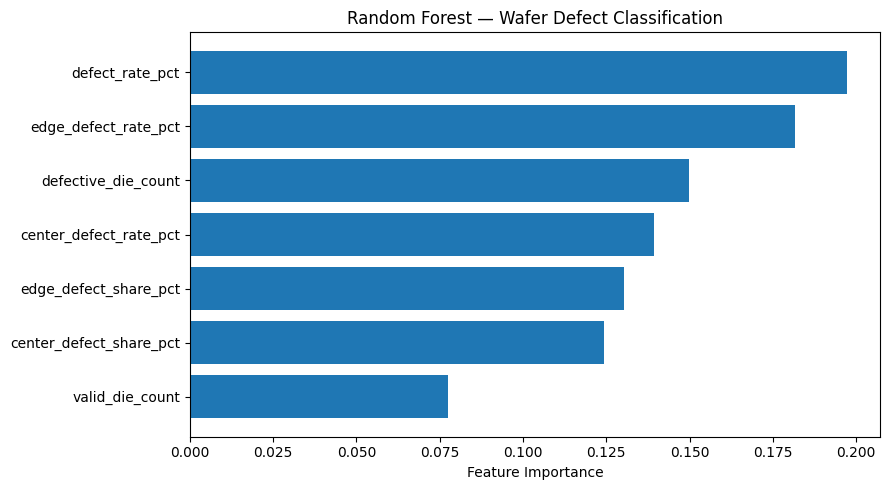

In [ ]:

# PHASE 5 — STEP 3: Random Forest feature importance

import pandas as pd
import matplotlib.pyplot as plt

rf = corrected_model.named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

print("Feature importance ranking:")
print(importance_df.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)
plt.xlabel("Feature Importance")
plt.title("Random Forest — Wafer Defect Classification")
plt.tight_layout()
plt.show()


In [ ]:

# PHASE 6 — Compare Random Forest vs Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)
import pandas as pd

# Logistic Regression pipeline
lr_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Train and predict on the same split
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# Compare both models
comparison_df = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0)
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, lr_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, lr_pred),
        "Macro F1": f1_score(y_test, lr_pred, average="macro", zero_division=0)
    }
])

print(comparison_df.round(4).to_string(index=False))


              Model  Accuracy  Balanced Accuracy  Macro F1
      Random Forest    0.5732             0.5043    0.4664
Logistic Regression    0.3902             0.5918    0.4737


In [ ]:

# PHASE 7 — Save final model comparison and feature importance

import os
import pandas as pd

output_dir = (
    "/content/drive/MyDrive/Wafer_Defect_Analysis/"
    "final_results"
)
os.makedirs(output_dir, exist_ok=True)

# Save comparison of both models
comparison_df.to_csv(
    os.path.join(output_dir, "model_comparison.csv"),
    index=False
)

# Save feature importance from the corrected Random Forest
importance_df.to_csv(
    os.path.join(output_dir, "feature_importance.csv"),
    index=False
)

# Save predictions from both models for the same test wafers
predictions_df = pd.DataFrame({
    "actual_label": y_test.to_numpy(),
    "random_forest_prediction": y_pred,
    "logistic_regression_prediction": lr_pred
})

predictions_df.to_csv(
    os.path.join(output_dir, "model_predictions.csv"),
    index=False
)

print("Final results saved to:", output_dir)
print("\nFiles:")
print("- model_comparison.csv")
print("- feature_importance.csv")
print("- model_predictions.csv")


Final results saved to: /content/drive/MyDrive/Wafer_Defect_Analysis/final_results

Files:
- model_comparison.csv
- feature_importance.csv
- model_predictions.csv


In [ ]:

# REPLACE OLD PHASE 3 RESULTS WITH CORRECTED RESULTS

import os
import pandas as pd

phase3_dir = (
    "/content/drive/MyDrive/Wafer_Defect_Analysis/"
    "phase3_results"
)

os.makedirs(phase3_dir, exist_ok=True)

# Save the corrected metrics for all 410 labelled wafers
corrected_df.to_csv(
    os.path.join(phase3_dir, "wafer_defect_metrics.csv"),
    index=False
)

# Recalculate the summary by defect category
category_summary = (
    corrected_df.groupby("defect_label")
    .agg(
        wafer_count=("source_index", "count"),
        mean_defect_rate_pct=("defect_rate_pct", "mean"),
        median_defect_rate_pct=("defect_rate_pct", "median"),
        mean_center_defect_rate_pct=("center_defect_rate_pct", "mean"),
        mean_edge_defect_rate_pct=("edge_defect_rate_pct", "mean")
    )
    .reset_index()
)

category_summary.to_csv(
    os.path.join(phase3_dir, "defect_category_summary.csv"),
    index=False
)

print("Phase 3 results updated successfully.")
print("Folder:", phase3_dir)
print("\nCorrected metrics:", len(corrected_df), "wafers")
print("\nUpdated category summary:")
print(category_summary.round(2).to_string(index=False))


Phase 3 results updated successfully.
Folder: /content/drive/MyDrive/Wafer_Defect_Analysis/phase3_results

Corrected metrics: 410 wafers

Updated category summary:
defect_label  wafer_count  mean_defect_rate_pct  median_defect_rate_pct  mean_center_defect_rate_pct  mean_edge_defect_rate_pct
      Center           25                 23.50                   22.70                        42.75                      17.13
       Donut           25                 31.69                   31.57                        61.48                      21.79
    Edge-Loc          151                 24.26                   22.89                        17.56                      26.41
   Edge-Ring           35                 26.16                   26.73                        15.88                      29.44
         Loc          115                 16.28                   16.70                        15.38                      16.59
   Near-full            8                 90.06                   91